# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Куролёнок Карина Юрьевна
**Файлы данных:** S15

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = 'data/S15/clients.csv'
RAW_TXN = 'data/S15/transactions.csv'

PERIOD_2024_START = pd.Timestamp("2024-01-01")
PERIOD_2024_END = pd.Timestamp("2024-12-31 23:59:59")
PERIOD_2025_START = pd.Timestamp("2025-01-01")
PERIOD_2025_END = pd.Timestamp("2025-06-30 23:59:59")
SNAPSHOT_DATE = pd.Timestamp("2025-06-30")

DAYS_PER_MONTH = 365.2425 / 12
CAMPAIGN_LIMIT = 2000
MIN_GROUP_SIZE = 150


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [96]:
raw_clients = pd.read_csv(
    RAW_CLIENTS,
    sep=",",
    decimal=".",
    encoding="utf-8",
    dtype={"branch_code": "string", "client_id": "string"},
)

raw_transactions = pd.read_csv(
    RAW_TXN,
    sep=";",
    decimal=",",
    encoding="cp1251",
    dtype={"client_id": "string"},
)

required_clients = {
    "client_id",
    "birth_date",
    "gender",
    "city",
    "segment",
    "loyalty_tier",
    "card_type",
    "registration_date",
    "card_open_date",
    "income_source",
    "monthly_income",
    "has_mobile_app",
    "app_last_login",
    "satisfaction_score",
    "branch_code",
    "marketing_opt_in",
}
required_txn = {
    "txn_id",
    "client_id",
    "txn_datetime",
    "amount",
    "currency",
    "category",
    "mcc_code",
    "channel",
    "status",
}

assert required_clients.issubset(
    raw_clients.columns
), "В clients отсутствуют обязательные поля!"
assert required_txn.issubset(
    raw_transactions.columns
), "В transactions отсутствуют обязательные поля!"

print(
    f"Загружено: clients = {raw_clients.shape[0]:,} строк | transactions = {raw_transactions.shape[0]:,} строк"
)
display(raw_clients.head(2))
display(raw_transactions.head(2))

Загружено: clients = 5,670 строк | transactions = 619,916 строк


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001919,1968-10-29,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,14.06.2011,13.02.2016,Зарплата в нашем банке,53500.0,Да,2024-10,NaN,00100,Да
1,C002920,1954-10-07,М,СПб,Массовый,Золото,Кредитная,02.04.2012,16.10.2016,Зарплата в другом банке,125500.0,Да,2024-03,2.0,00120,Да


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990124,C000052,2023-11-26 15:27:11,5482.85,RUB,Одежда и обувь,5651,Карта,успешно
1,990022,C002010,2023-12-10 11:38:58,1606.39,RUB,Аптеки,5912,СБП,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [98]:
display(pd.DataFrame([
    {
        'Таблица': 'clients',
        'Единица наблюдения': 'Клиент (физлицо)',
        'Строк (N)': len(raw_clients),
        'Колонок': raw_clients.shape[1],
        'Первичный ключ': 'client_id',
        'Уникальных ID (U)': raw_clients['client_id'].nunique(),
        'Лишних записей ключа': len(raw_clients) - raw_clients['client_id'].nunique(),
        'Доля небиективности': f"{(len(raw_clients) - raw_clients['client_id'].nunique()) / len(raw_clients):.2%}"
    },
    {
        'Таблица': 'transactions',
        'Единица наблюдения': 'Транзакция по карте',
        'Строк (N)': len(raw_transactions),
        'Колонок': raw_transactions.shape[1],
        'Первичный ключ': 'txn_id',
        'Уникальных ID (U)': raw_transactions['txn_id'].nunique(),
        'Лишних записей ключа': len(raw_transactions) - raw_transactions['txn_id'].nunique(),
        'Доля небиективности': f"{(len(raw_transactions) - raw_transactions['txn_id'].nunique()) / len(raw_transactions):.2%}"
    }
]))

types_c = pd.DataFrame({'Колонка clients': raw_clients.columns, 'Тип': raw_clients.dtypes.values.astype(str)})
types_t = pd.DataFrame({'Колонка transactions': raw_transactions.columns, 'Тип': raw_transactions.dtypes.values.astype(str)})
display(pd.concat([types_c, types_t], axis=1).fillna(''))

,Таблица,Единица наблюдения,Строк (N),Колонок,Первичный ключ,Уникальных ID (U),Лишних записей ключа,Доля небиективности
0,clients,Клиент (физлицо),5670,16,client_id,5615,55,0.97%
1,transactions,Транзакция по карте,619916,9,txn_id,618416,1500,0.24%


,Колонка clients,Тип,Колонка transactions,Тип
0,client_id,string,txn_id,int64
1,birth_date,str,client_id,string
2,gender,str,txn_datetime,str
3,city,str,amount,float64
4,segment,str,currency,str
5,loyalty_tier,str,category,str
6,card_type,str,mcc_code,int64
7,registration_date,str,channel,str
8,card_open_date,str,status,str
9,income_source,str,,


### 2.2. Дубли

In [99]:
def audit_duplicates(df, key_col):
    n_total = len(df)
    n_clones = int(df.duplicated().sum())
    after_clones = df.drop_duplicates()
    conflict_mask = after_clones.duplicated(subset=[key_col], keep=False)
    conf_keys = after_clones.loc[conflict_mask, key_col].dropna().unique()
    return (
        n_total,
        n_clones,
        len(conf_keys),
        int(conflict_mask.sum()),
        conf_keys,
        after_clones,
    )


(
    c_tot,
    c_clones,
    c_conf_keys,
    c_conf_rows,
    c_conf_ids,
    dedup_c,
) = audit_duplicates(raw_clients, "client_id")
(
    t_tot,
    t_clones,
    t_conf_keys,
    t_conf_rows,
    t_conf_ids,
    dedup_t,
) = audit_duplicates(raw_transactions, "txn_id")

display(
    pd.DataFrame(
        [
            {
                "Таблица": "clients",
                "Строк (N)": c_tot,
                "Клон-дубли": c_clones,
                "Доля клонов": f"{c_clones/c_tot:.2%}",
                "Конфликтных ID": c_conf_keys,
                "Строк с конфликтами": c_conf_rows,
            },
            {
                "Таблица": "transactions",
                "Строк (N)": t_tot,
                "Клон-дубли": t_clones,
                "Доля клонов": f"{t_clones/t_tot:.2%}",
                "Конфликтных ID": t_conf_keys,
                "Строк с конфликтами": t_conf_rows,
            },
        ]
    )
)

conf_t_sample = dedup_t[dedup_t["txn_id"].isin(t_conf_ids)]
midnight_conflicts = conf_t_sample["txn_datetime"].str.contains(
    "00:00:00", na=False
)
print(
    f"Конфликтующих записей txn_id со временем 00:00:00: {midnight_conflicts.sum()} из {len(conf_t_sample)}"
)

,Таблица,Строк (N),Клон-дубли,Доля клонов,Конфликтных ID,Строк с конфликтами
0,clients,5670,40,0.71%,15,30
1,transactions,619916,1266,0.20%,234,468


Конфликтующих записей txn_id со временем 00:00:00: 0 из 468


### 2.3. Соответствие данных описанию полей из задания

In [101]:
missing_records = []
for name, df in [("clients", raw_clients), ("transactions", raw_transactions)]:
    null_counts = df.isna().sum()
    for col in df.columns:
        if null_counts[col] > 0:
            missing_records.append(
                {
                    "Таблица": name,
                    "Колонка": col,
                    "Пропусков (шт)": null_counts[col],
                    "Доля от N": f"{null_counts[col] / len(df):.2%}",
                }
            )
print("1. ПРОПУСКИ В ДАННЫХ:")
display(pd.DataFrame(missing_records))

num_records = [
    {
        "Поле": f"{tbl}.{col}",
        "Min": s.min(),
        "Max": s.max(),
        "Значений < 0": (s < 0).sum(),
        "Значений == 0": (s == 0).sum(),
    }
    for tbl, col, s in [
        ("clients", "monthly_income", raw_clients["monthly_income"]),
        ("clients", "satisfaction_score", raw_clients["satisfaction_score"]),
        ("transactions", "amount", raw_transactions["amount"]),
    ]
]
print("\n2. ЧИСЛОВЫЕ МЕТРИКИ:")
display(pd.DataFrame(num_records))

display(
    raw_transactions.loc[raw_transactions["amount"] < 0, "status"]
    .value_counts()
    .rename("Статус отрицательных amount")
    .to_frame()
)

print("\n3. ВАЛЮТЫ ТРАНЗАКЦИЙ:")
display(
    raw_transactions["currency"].value_counts(dropna=False).to_frame("Кол-во")
)

1. ПРОПУСКИ В ДАННЫХ:


,Таблица,Колонка,Пропусков (шт),Доля от N
0,clients,monthly_income,532,9.38%
1,clients,app_last_login,2103,37.09%
2,clients,satisfaction_score,3359,59.24%



2. ЧИСЛОВЫЕ МЕТРИКИ:


,Поле,Min,Max,Значений < 0,Значений == 0
0,clients.monthly_income,-999.00,1052900.00,56,0
1,clients.satisfaction_score,1.00,5.00,0,0
2,transactions.amount,-60058.31,152959.72,7285,0


,Статус отрицательных amount
status,
возврат,7285



3. ВАЛЮТЫ ТРАНЗАКЦИЙ:


,Кол-во
currency,
RUB,617524
EUR,1223
USD,1169


### 2.4. Связь между таблицами

In [102]:
c_ids = set(raw_clients["client_id"].dropna())
t_ids = set(raw_transactions["client_id"].dropna())
orphan_tx = raw_transactions["client_id"].isin(t_ids - c_ids).sum()

display(
    pd.DataFrame(
        [
            {
                "Метрика": "Уникальных клиентов в clients",
                "Кол-во": len(c_ids),
                "Доля от N_clients": "100.00%",
            },
            {
                "Метрика": "Клиентов с операциями",
                "Кол-во": len(c_ids & t_ids),
                "Доля от N_clients": f"{len(c_ids & t_ids)/len(c_ids):.2%}",
            },
            {
                "Метрика": "Клиентов без операций",
                "Кол-во": len(c_ids - t_ids),
                "Доля от N_clients": f"{len(c_ids - t_ids)/len(c_ids):.2%}",
            },
            {
                "Метрика": "Транзакций без клиента (в сырых)",
                "Кол-во": orphan_tx,
                "Доля от N_transactions": f"{orphan_tx / len(raw_transactions):.2%}",
            },
        ]
    )
)

,Метрика,Кол-во,Доля от N_clients,Доля от N_transactions
0,Уникальных клиентов в clients,5615,100.00%,NaN
1,Клиентов с операциями,5611,99.93%,NaN
2,Клиентов без операций,4,0.07%,NaN
3,Транзакций без клиента (в сырых),30647,NaN,4.94%


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

1. **Ключи и дубли:**
   - `clients`: 40 полных клонов (0.71% от 5 670 строк) и 15 коллизий ID (30 строк, 0.53%). Конфликтные ID удаляем целиком — не понятно какие из них верные, вводят в заблуждение.
   - `transactions`: 1 266 клонов (0.20% от 619 916 строк) и 234 коллизии `txn_id` (468 строк, 0.08%).
2. 30 647 транзакций (4.94% от 619 916) без связи с `clients`. Исключаем — клиентов по ним идентифицировать нельзя, поэтому к данному анализу не подходят.
3. **Период:** транзакции вне ТЗ (`2024-01-01 .. 2025-06-30`). Отсекаем.
4. **Числовые аномалии:**
   - `monthly_income == -999.00` (56 строк, 0.99% от 5 670) — технический маркер пропуска, заменяем на `NaN`.
   - `amount < 0` (7 285 строк, 1.18% от 619 916) — 100% операции со статусом «возврат». Оставляем с минусом для корректного сальдо трат.
5. **Текстовая грязь:** 17 вариантов написания городов вместо базовых и 12 категорий вместо 9 (ошибки регистра и разделителей). Требуется нормализация.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [113]:
log_records = []


def log(field, issue, scope, n_rows, before, action, after, rationale):
    log_records.append(
        {
            "field": field,
            "issue": issue,
            "scope": scope,
            "n_rows": int(n_rows),
            "value_before": str(before),
            "action": action,
            "value_after": str(after),
            "rationale": rationale,
        }
    )


df_clients = raw_clients.copy()
df_transactions = raw_transactions.copy()


date_cols_clients = [
    "birth_date",
    "registration_date",
    "card_open_date",
    "app_last_login",
]
for col in date_cols_clients:
    df_clients[col] = pd.to_datetime(df_clients[col], format="mixed")

df_transactions["txn_datetime"] = pd.to_datetime(
    df_transactions["txn_datetime"], format="mixed"
)
df_transactions["amount"] = pd.to_numeric(
    df_transactions["amount"], errors="coerce"
)
df_transactions["mcc_code"] = df_transactions["mcc_code"].astype("string")


mask_sentinel = df_clients["monthly_income"].eq(-999.0)
n_sentinel = int(mask_sentinel.sum())
df_clients.loc[mask_sentinel, "monthly_income"] = np.nan
log(
    "monthly_income",
    "системный маркер пропуска данных (-999)",
    "клиенты со значением -999",
    n_sentinel,
    "-999.00",
    "исправлено",
    "NaN",
    "Технический маркер отсутствия дохода переведён в NaN для корректных квантилей.",
)


invalid_registration = df_clients["registration_date"].gt(SNAPSHOT_DATE)
invalid_card_open = df_clients["card_open_date"].gt(SNAPSHOT_DATE)
df_clients["invalid_date"] = invalid_registration | invalid_card_open
n_invalid_dates = int(df_clients["invalid_date"].sum())

log(
    "registration_date/card_open_date",
    "дата позже даты среза",
    "клиенты с датой > 30.06.2025",
    n_invalid_dates,
    "даты из будущего",
    "помечено",
    "invalid_date=True",
    "Записи не удаляются, но помечаются флагом для исключения из маркетинга.",
)


print("ИТОГИ ПРИВЕДЕНИЯ ТИПОВ И ЧИСЕЛ:")
print(f"• Заменено системных маркеров -999 в доходе: {n_sentinel} шт.")
print(
    f"• Выявлено записей с датами позже даты среза (30.06.2025): {n_invalid_dates} шт."
)
print("\nПроверка типов колонок и корректности значений clients:")
display(
    df_clients[
        [
            "client_id",
            "birth_date",
            "registration_date",
            "card_open_date",
            "monthly_income",
            "invalid_date",
        ]
    ].head(3)
)
print("Проверка типов колонок transactions:")
display(
    df_transactions[
        ["txn_id", "client_id", "txn_datetime", "amount", "mcc_code"]
    ].head(3)
)

ИТОГИ ПРИВЕДЕНИЯ ТИПОВ И ЧИСЕЛ:
• Заменено системных маркеров -999 в доходе: 56 шт.
• Выявлено записей с датами позже даты среза (30.06.2025): 58 шт.

Проверка типов колонок и корректности значений clients:


,client_id,birth_date,registration_date,card_open_date,monthly_income,invalid_date
0,C001919,1968-10-29,2011-06-14,2016-02-13,53500.0,False
1,C002920,1954-10-07,2012-02-04,2016-10-16,125500.0,False
2,C000925,1973-02-04,2014-04-18,2016-05-27,69700.0,False


Проверка типов колонок transactions:


,txn_id,client_id,txn_datetime,amount,mcc_code
0,990124,C000052,2023-11-26 15:27:11,5482.85,5651
1,990022,C002010,2023-12-10 11:38:58,1606.39,5912
2,100001,C003676,2024-01-01 00:54:00,384.01,4111


### 3.2. Категориальные признаки

In [114]:
city_map = {
    "москва": "Москва",
    "москва ": "Москва",
    "москва,": "Москва",
    "г. москва": "Москва",
    "г.москва": "Москва",
    "санкт-петербург": "Санкт-Петербург",
    "санкт петербург": "Санкт-Петербург",
    "г. санкт-петербург": "Санкт-Петербург",
    "спб": "Санкт-Петербург",
    "екатеринбург": "Екатеринбург",
    "г.екатеринбург": "Екатеринбург",
    "нижний новгород": "Нижний Новгород",
    "н. новгород": "Нижний Новгород",
    "новосибирск": "Новосибирск",
    "г. новосибирск": "Новосибирск",
    "казань": "Казань",
}

city_before = df_clients["city"].astype("string")
city_norm = (
    city_before.str.strip().str.lower().map(city_map).fillna(city_before)
)
n_city_changed = int((city_norm != city_before).fillna(False).sum())
df_clients["city"] = city_norm
log(
    "city",
    "разнобой написания городов",
    "все строки clients",
    n_city_changed,
    "17 вариантов",
    "исправлено",
    "6 канонических городов РФ",
    "Приведено к единому классификатору без изменения смысла.",
)

category_map = {
    "кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
    "связь и интернет": "Связь и интернет",
}
cat_before = df_transactions["category"].astype("string")
cat_norm = (
    cat_before.str.strip()
    .str.lower()
    .map(category_map)
    .fillna(cat_before.str.strip())
)
n_cat_changed = int((cat_norm != cat_before).fillna(False).sum())
df_transactions["category"] = cat_norm
log(
    "category",
    "разнобой регистра и слэшей",
    "все строки transactions",
    n_cat_changed,
    "12 вариантов",
    "исправлено",
    "9 категорий ТЗ",
    "Устранены дубли категорий из-за регистра и написания слэша.",
)

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [115]:
display(
    pd.DataFrame(
        [
            {
                "Поле": "app_last_login",
                "Пропусков": df_clients["app_last_login"].isna().sum(),
                "Механизм": "Структурный / MAR",
                "Обоснование": "Пропуск закономерен для клиентов без приложения (has_mobile_app == 'Нет').",
                "Решение": "Оставлено NaN (заполнение создаст ложных пользователей).",
            },
            {
                "Поле": "satisfaction_score",
                "Пропусков": df_clients["satisfaction_score"].isna().sum(),
                "Механизм": "MNAR",
                "Обоснование": "Добровольный опрос с неполным откликом (59% пропусков).",
                "Решение": "Оставлено NaN (импутация сместит истинные оценки удовлетворенности).",
            },
            {
                "Поле": "monthly_income",
                "Пропусков": df_clients["monthly_income"].isna().sum(),
                "Механизм": "MNAR",
                "Обоснование": "Отказ части клиентов раскрывать доход (+ маркеры -999).",
                "Решение": "Оставлено NaN (сохраняем исходное распределение).",
            },
        ]
    )
)

,Поле,Пропусков,Механизм,Обоснование,Решение
0,app_last_login,2103,Структурный / MAR,Пропуск закономерен для клиентов без приложени...,Оставлено NaN (заполнение создаст ложных польз...
1,satisfaction_score,3359,MNAR,Добровольный опрос с неполным откликом (59% пр...,Оставлено NaN (импутация сместит истинные оцен...
2,monthly_income,588,MNAR,Отказ части клиентов раскрывать доход (+ марке...,Оставлено NaN (сохраняем исходное распределение).


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [116]:
def find_iqr_outliers(series, name):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    outliers = s[s > upper_fence]
    return {
        "Признак": name,
        "N": len(s),
        "Медиана": s.median(),
        "Q1": q1,
        "Q3": q3,
        "Граница IQR": upper_fence,
        "Выбросов": len(outliers),
        "Доля": f"{len(outliers)/len(s):.2%}",
    }


display(
    pd.DataFrame(
        [
            find_iqr_outliers(df_clients["monthly_income"], "monthly_income"),
            find_iqr_outliers(
                df_transactions.loc[
                    df_transactions["amount"] > 0, "amount"
                ],
                "amount",
            ),
        ]
    )
)


log(
    "monthly_income",
    "значения выше границы IQR (>197k ₽)",
    "клиенты с высоким доходом",
    find_iqr_outliers(df_clients["monthly_income"], "")["Выбросов"],
    "до 1.05 млн ₽",
    "оставлено",
    "исходные значения",
    "Высокие доходы подтверждены сегментами Премиум и Private; отражают реальную клиентуру.",
)
log(
    "amount",
    "суммы операций выше границы IQR (>5k ₽)",
    "крупные чеки",
    find_iqr_outliers(
        df_transactions.loc[df_transactions["amount"] > 0, "amount"], ""
    )["Выбросов"],
    "до 152k ₽",
    "оставлено",
    "исходные значения",
    "Крупные покупки (электроника, отели) экономически легитимны.",
)

,Признак,N,Медиана,Q1,Q3,Граница IQR,Выбросов,Доля
0,monthly_income,5082,75000.00,52300.00,110200.000,197050.0000,380,7.48%
1,amount,612631,1089.52,486.12,2297.285,5014.0325,50338,8.22%


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [117]:
n_c_raw = len(df_clients)
df_c_step1 = df_clients.drop_duplicates()
n_c_clones = n_c_raw - len(df_c_step1)

conf_client_ids = df_c_step1.loc[
    df_c_step1["client_id"].duplicated(keep=False), "client_id"
].unique()
clean_clients = df_c_step1[
    ~df_c_step1["client_id"].isin(conf_client_ids)
].copy()
n_c_conflicts = len(df_c_step1) - len(clean_clients)

log(
    "client_id",
    "полные дубликаты записей",
    "клиенты",
    n_c_clones,
    "повторы",
    "удалено",
    "уникальные строки",
    "Удаление технического сбоя дублирования строк.",
)
log(
    "client_id",
    "конфликты атрибутов ключа",
    "клиенты",
    n_c_conflicts,
    f"{len(conf_client_ids)} коллизий",
    "удалено",
    "исключены все строки ID",
    "Невозможно определить достоверную карточку без дополнительного источника.",
)

n_t_raw = len(df_transactions)
df_t_step1 = df_transactions.drop_duplicates().copy()
n_t_clones = n_t_raw - len(df_t_step1)

dup_txn_key = df_t_step1["txn_id"].duplicated(keep=False)
conf_txn_ids = df_t_step1.loc[dup_txn_key, "txn_id"].unique()
conflict_txn_rows = df_t_step1[dup_txn_key].copy()


df_t_step2 = df_t_step1[~df_t_step1["txn_id"].isin(conf_txn_ids)].copy()
n_t_quarantine = len(conflict_txn_rows)

log(
    "txn_id",
    "полные дубли строк",
    "транзакции",
    n_t_clones,
    "повторы",
    "удалено",
    "уникальные строки",
    "Удалены идентичные повторы транзакций.",
)
log(
    "txn_id",
    "конфликтующие txn_id с разными полями",
    "транзакции",
    n_t_quarantine,
    f"{len(conf_txn_ids)} ID",
    "исключено в карантин",
    "исключены все строки коллизий",
    "Отказ от недоказанной эвристики полуночи: конфликты изолированы.",
)


mask_period = df_t_step2["txn_datetime"].between(
    PERIOD_2024_START, PERIOD_2025_END
)
df_t_step3 = df_t_step2[mask_period].copy()
n_t_period = len(df_t_step2) - len(df_t_step3)

log(
    "txn_datetime",
    "операции вне периода ТЗ",
    "транзакции",
    n_t_period,
    "2023 и 2026 гг.",
    "ограничено",
    "2024-01-01 .. 2025-06-30",
    "Анализ ограничен временным окном ТЗ.",
)


clean_client_ids = set(clean_clients["client_id"])
raw_client_ids = set(raw_clients["client_id"].dropna())

orphan_due_to_removed_clients = df_t_step3["client_id"].isin(
    set(conf_client_ids)
)
orphan_due_to_unknown_ids = ~df_t_step3["client_id"].isin(raw_client_ids)
orphan_total_mask = ~df_t_step3["client_id"].isin(clean_client_ids)

clean_transactions = df_t_step3[~orphan_total_mask].copy().reset_index(drop=True)
n_t_orphans = int(orphan_total_mask.sum())

display(
    pd.DataFrame(
        [
            {
                "Показатель": "Сироты из-за удаления конфликтующих клиентов",
                "Строк": int(orphan_due_to_removed_clients.sum()),
            },
            {
                "Показатель": "Сироты, отсутствующие даже в сыром clients",
                "Строк": int(orphan_due_to_unknown_ids.sum()),
            },
            {
                "Показатель": "ИТОГО удалено транзакций-сирот",
                "Строк": n_t_orphans,
            },
        ]
    )
)


assert n_t_orphans == int(orphan_due_to_removed_clients.sum()) + int(
    orphan_due_to_unknown_ids.sum()
)

log(
    "client_id",
    "транзакции без профиля клиента",
    "транзакции",
    n_t_orphans,
    "без клиента",
    "удалено",
    "только верифицированные клиенты",
    "Без профиля клиента нельзя проверить согласие и признаки.",
)


funnel_tx = pd.DataFrame(
    [
        ["0. Исходные операции", 0, len(raw_transactions), "100.00%"],
        [
            "1. Удаление полных дублей",
            n_t_clones,
            len(df_t_step1),
            f"{len(df_t_step1)/len(raw_transactions):.2%}",
        ],
        [
            "2. Карантин конфликтующих txn_id",
            n_t_quarantine,
            len(df_t_step2),
            f"{len(df_t_step2)/len(raw_transactions):.2%}",
        ],
        [
            "3. Отсечение дат вне периода ТЗ",
            n_t_period,
            len(df_t_step3),
            f"{len(df_t_step3)/len(raw_transactions):.2%}",
        ],
        [
            "4. Исключение транзакций-сирот",
            n_t_orphans,
            len(clean_transactions),
            f"{len(clean_transactions)/len(raw_transactions):.2%}",
        ],
    ],
    columns=["Шаг фильтрации", "Исключено", "Осталось", "Доля от исх."],
)

display(funnel_tx)

,Показатель,Строк
0,Сироты из-за удаления конфликтующих клиентов,1548
1,"Сироты, отсутствующие даже в сыром clients",30556
2,ИТОГО удалено транзакций-сирот,32104


,Шаг фильтрации,Исключено,Осталось,Доля от исх.
0,0. Исходные операции,0,619916,100.00%
1,1. Удаление полных дублей,1266,618650,99.80%
2,2. Карантин конфликтующих txn_id,468,618182,99.72%
3,3. Отсечение дат вне периода ТЗ,82,618100,99.71%
4,4. Исключение транзакций-сирот,32104,585996,94.53%


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [69]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [118]:
cleaning_log = pd.DataFrame(
    log_records,
    columns=[
        "field",
        "issue",
        "scope",
        "n_rows",
        "value_before",
        "action",
        "value_after",
        "rationale",
    ],
)

print(f"Всего зафиксировано решений: {len(cleaning_log)} шт.\n")
display(cleaning_log)

Всего зафиксировано решений: 12 шт.



,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,monthly_income,системный маркер пропуска данных (-999),клиенты со значением -999,56,-999.00,исправлено,NaN,Технический маркер отсутствия дохода переведён...
1,registration_date/card_open_date,дата позже даты среза,клиенты с датой > 30.06.2025,58,даты из будущего,помечено,invalid_date=True,"Записи не удаляются, но помечаются флагом для ..."
2,city,разнобой написания городов,все строки clients,1678,17 вариантов,исправлено,6 канонических городов РФ,Приведено к единому классификатору без изменен...
3,category,разнобой регистра и слэшей,все строки transactions,51302,12 вариантов,исправлено,9 категорий ТЗ,Устранены дубли категорий из-за регистра и нап...
4,monthly_income,значения выше границы IQR (>197k ₽),клиенты с высоким доходом,380,до 1.05 млн ₽,оставлено,исходные значения,Высокие доходы подтверждены сегментами Премиум...
5,amount,суммы операций выше границы IQR (>5k ₽),крупные чеки,50338,до 152k ₽,оставлено,исходные значения,"Крупные покупки (электроника, отели) экономиче..."
6,client_id,полные дубликаты записей,клиенты,40,повторы,удалено,уникальные строки,Удаление технического сбоя дублирования строк.
7,client_id,конфликты атрибутов ключа,клиенты,30,15 коллизий,удалено,исключены все строки ID,Невозможно определить достоверную карточку без...
8,txn_id,полные дубли строк,транзакции,1266,повторы,удалено,уникальные строки,Удалены идентичные повторы транзакций.
9,txn_id,конфликтующие txn_id с разными полями,транзакции,468,234 ID,исключено в карантин,исключены все строки коллизий,Отказ от недоказанной эвристики полуночи: конф...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

,Признак,N (валидных),Пропусков,Среднее,Стд. откл.,Мин,25% (Q1),Медиана,75% (Q3),IQR,Макс,Скошенность (skew)
0,Возраст (лет),5600,0,53.26,13.93,20.00,43.00,51.00,62.00,19.00,88.00,0.52
1,Стаж клиента (лет),5600,0,7.84,3.21,-0.42,5.46,7.90,10.25,4.78,15.40,-0.06
2,Ежемесячный доход (₽),5018,582,95941.92,82908.09,25.90,52300.00,75000.00,110200.00,57900.00,1052900.00,3.55
3,Сумма покупки (RUB),565329,0,1915.59,2668.53,3.66,489.34,1089.43,2286.38,1797.04,152959.72,5.40


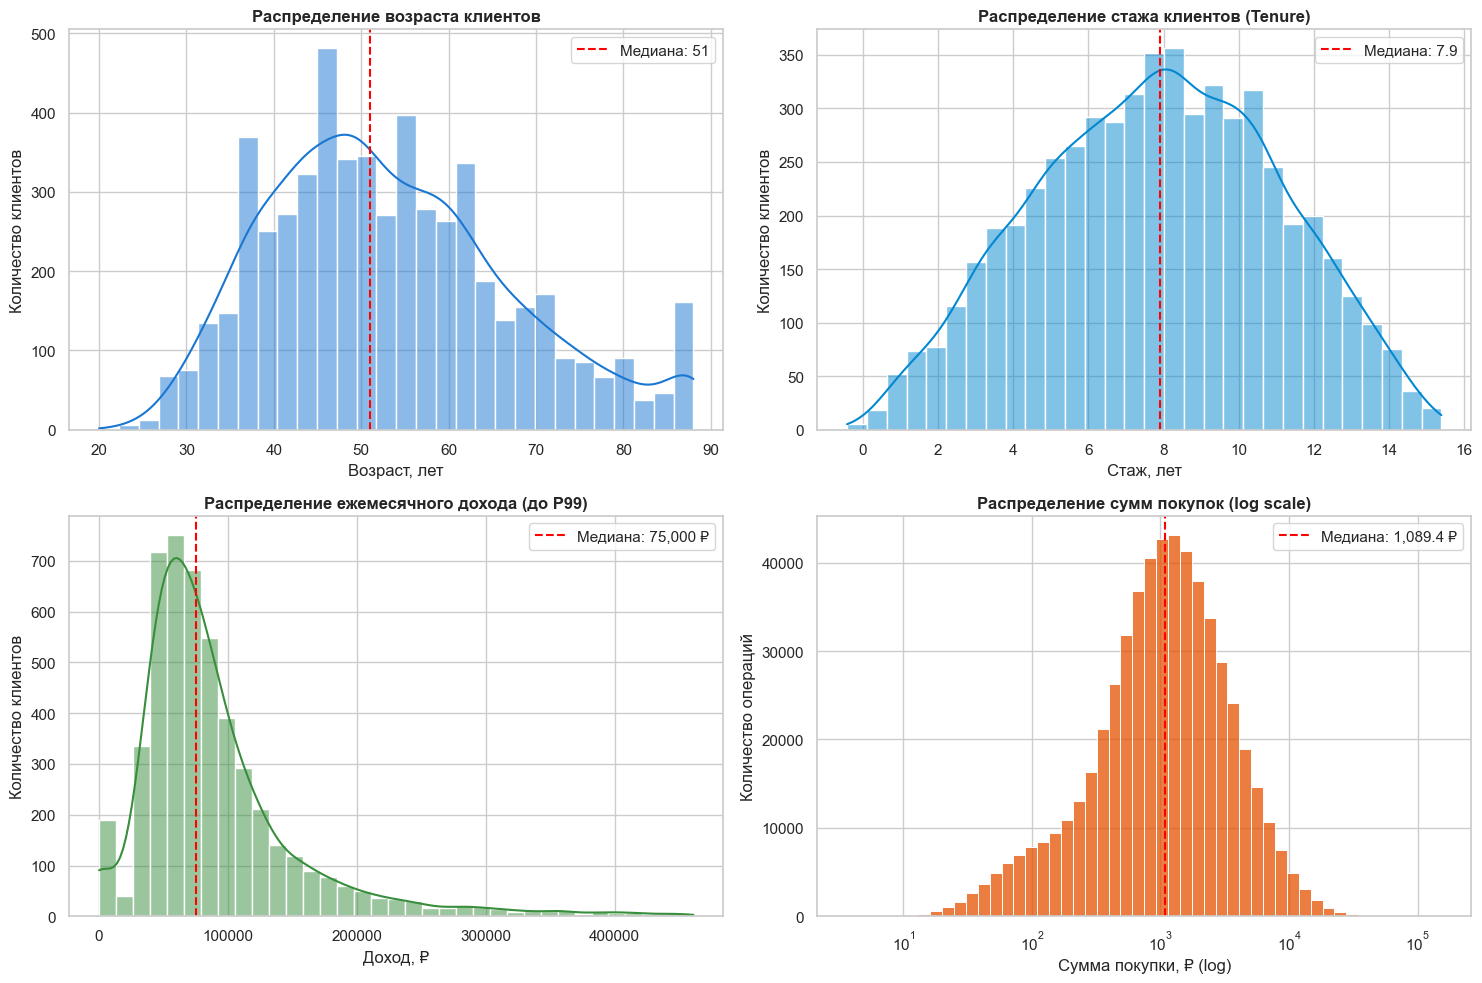

In [119]:
clean_clients["age"] = (
    SNAPSHOT_DATE - clean_clients["birth_date"]
).dt.days // 365.25
clean_clients["tenure_years"] = (
    SNAPSHOT_DATE - clean_clients["registration_date"]
).dt.days / (365.2425 / 12) / 12

rub_amounts = clean_transactions.loc[
    (clean_transactions["status"] == "успешно")
    & (clean_transactions["currency"] == "RUB")
    & (clean_transactions["amount"] > 0),
    "amount",
]

num_features = {
    "Возраст (лет)": clean_clients["age"],
    "Стаж клиента (лет)": clean_clients["tenure_years"],
    "Ежемесячный доход (₽)": clean_clients["monthly_income"],
    "Сумма покупки (RUB)": rub_amounts,
}

stats_list = []
for name, s in num_features.items():
    sc = s.dropna()
    q1 = sc.quantile(0.25)
    q3 = sc.quantile(0.75)
    stats_list.append(
        {
            "Признак": name,
            "N (валидных)": len(sc),
            "Пропусков": s.isna().sum(),
            "Среднее": round(sc.mean(), 2),
            "Стд. откл.": round(sc.std(), 2),
            "Мин": round(sc.min(), 2),
            "25% (Q1)": round(q1, 2),
            "Медиана": round(sc.median(), 2),
            "75% (Q3)": round(q3, 2),
            "IQR": round(q3 - q1, 2),
            "Макс": round(sc.max(), 2),
            "Скошенность (skew)": round(sc.skew(), 2),
        }
    )

display(pd.DataFrame(stats_list))


fig, axes = plt.subplots(2, 2, figsize=(15, 10))


sns.histplot(
    clean_clients["age"], bins=30, kde=True, ax=axes[0, 0], color="#1976d2"
)
axes[0, 0].axvline(
    clean_clients["age"].median(),
    color="red",
    linestyle="--",
    label=f'Медиана: {clean_clients["age"].median():.0f}',
)
axes[0, 0].set_title("Распределение возраста клиентов", fontweight="bold")
axes[0, 0].set_xlabel("Возраст, лет")
axes[0, 0].set_ylabel("Количество клиентов")
axes[0, 0].legend()


sns.histplot(
    clean_clients["tenure_years"],
    bins=30,
    kde=True,
    ax=axes[0, 1],
    color="#0288d1",
)
axes[0, 1].axvline(
    clean_clients["tenure_years"].median(),
    color="red",
    linestyle="--",
    label=f'Медиана: {clean_clients["tenure_years"].median():.1f}',
)
axes[0, 1].set_title(
    "Распределение стажа клиентов (Tenure)", fontweight="bold"
)
axes[0, 1].set_xlabel("Стаж, лет")
axes[0, 1].set_ylabel("Количество клиентов")
axes[0, 1].legend()


p99_inc = clean_clients["monthly_income"].quantile(0.99)
income_sub = clean_clients.loc[
    clean_clients["monthly_income"] <= p99_inc, "monthly_income"
]
sns.histplot(income_sub, bins=35, kde=True, ax=axes[1, 0], color="#388e3c")
axes[1, 0].axvline(
    clean_clients["monthly_income"].median(),
    color="red",
    linestyle="--",
    label=f'Медиана: {clean_clients["monthly_income"].median():,.0f} ₽',
)
axes[1, 0].set_title("Распределение ежемесячного дохода (до P99)", fontweight="bold")
axes[1, 0].set_xlabel("Доход, ₽")
axes[1, 0].set_ylabel("Количество клиентов")
axes[1, 0].legend()


sns.histplot(
    rub_amounts, bins=50, log_scale=True, ax=axes[1, 1], color="#e65100"
)
axes[1, 1].axvline(
    rub_amounts.median(),
    color="red",
    linestyle="--",
    label=f"Медиана: {rub_amounts.median():,.1f} ₽",
)
axes[1, 1].set_title(
    "Распределение сумм покупок (log scale)", fontweight="bold"
)
axes[1, 1].set_xlabel("Сумма покупки, ₽ (log)")
axes[1, 1].set_ylabel("Количество операций")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### 5.2. Частотные характеристики категориальных признаков

--- СТРУКТУРА КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ БАЗЫ ---


,segment,Количество (n),Доля,Знаменатель N
0,Массовый,2885,51.52 %,5600
1,Зарплатный,1527,27.27 %,5600
2,Премиальный,959,17.12 %,5600
3,Private,229,4.09 %,5600


,loyalty_tier,Количество (n),Доля,Знаменатель N
0,Базовый,2797,49.95 %,5600
1,Серебро,1521,27.16 %,5600
2,Золото,983,17.55 %,5600
3,Платина,299,5.34 %,5600


,card_type,Количество (n),Доля,Знаменатель N
0,Дебетовая,3839,68.55 %,5600
1,Кредитная,1247,22.27 %,5600
2,Премиальная,514,9.18 %,5600


,city,Количество (n),Доля,Знаменатель N
0,Москва,1579,28.2 %,5600
1,Нижний Новгород,969,17.3 %,5600
2,Санкт-Петербург,967,17.27 %,5600
3,Екатеринбург,721,12.88 %,5600
4,Новосибирск,709,12.66 %,5600
5,Казань,655,11.7 %,5600


,has_mobile_app,Количество (n),Доля,Знаменатель N
0,Да,3526,62.96 %,5600
1,Нет,2074,37.04 %,5600


,marketing_opt_in,Количество (n),Доля,Знаменатель N
0,Да,4932,88.07 %,5600
1,Нет,668,11.93 %,5600


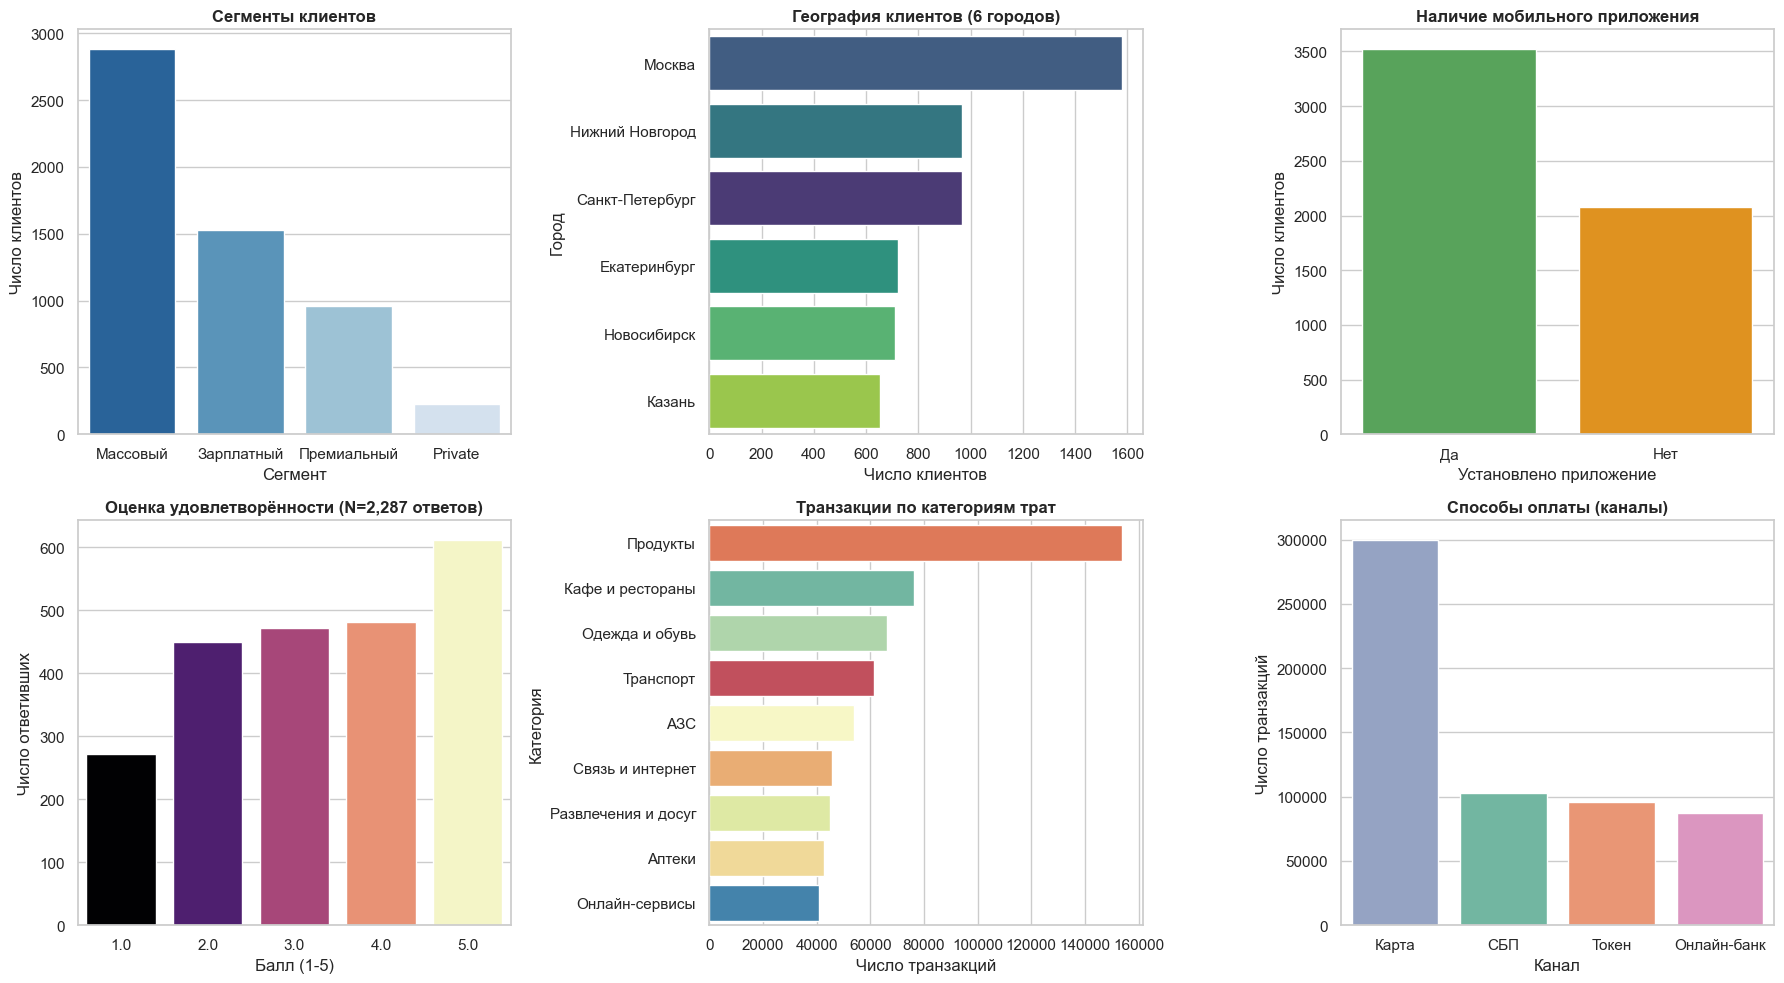

In [123]:
def display_freq(series, name):
    n = len(series)
    vc = series.value_counts(dropna=False).reset_index()
    vc.columns = [name, "Количество (n)"]
    vc["Доля"] = ((vc["Количество (n)"] / n * 100).round(2).astype(str) + " %")
    vc["Знаменатель N"] = n
    return vc

print("--- СТРУКТУРА КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ БАЗЫ ---")
for col in ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "marketing_opt_in"]:
    display(display_freq(clean_clients[col], col))


fig, axes = plt.subplots(2, 3, figsize=(18, 10))


seg_order = ["Массовый", "Зарплатный", "Премиальный", "Private"]
sns.countplot(
    data=clean_clients,
    x="segment",
    order=seg_order,
    hue="segment",
    palette="Blues_r",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Сегменты клиентов", fontweight="bold")
axes[0, 0].set_xlabel("Сегмент")
axes[0, 0].set_ylabel("Число клиентов")


city_order = clean_clients["city"].value_counts().index
sns.countplot(
    data=clean_clients,
    y="city",
    order=city_order,
    hue="city",
    palette="viridis",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("География клиентов (6 городов)", fontweight="bold")
axes[0, 1].set_xlabel("Число клиентов")
axes[0, 1].set_ylabel("Город")


sns.countplot(
    data=clean_clients,
    x="has_mobile_app",
    hue="has_mobile_app",
    palette=["#4caf50", "#ff9800"],
    legend=False,
    ax=axes[0, 2]
)
axes[0, 2].set_title("Наличие мобильного приложения", fontweight="bold")
axes[0, 2].set_xlabel("Установлено приложение")
axes[0, 2].set_ylabel("Число клиентов")


sat_clients = clean_clients.dropna(subset=["satisfaction_score"])
sns.countplot(
    data=sat_clients,
    x="satisfaction_score",
    hue="satisfaction_score",
    palette="magma",
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title(f"Оценка удовлетворённости (N={len(sat_clients):,} ответов)", fontweight="bold")
axes[1, 0].set_xlabel("Балл (1-5)")
axes[1, 0].set_ylabel("Число ответивших")


cat_order = clean_transactions["category"].value_counts().index
sns.countplot(
    data=clean_transactions,
    y="category",
    order=cat_order,
    hue="category",
    palette="Spectral",
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Транзакции по категориям трат", fontweight="bold")
axes[1, 1].set_xlabel("Число транзакций")
axes[1, 1].set_ylabel("Категория")


ch_order = clean_transactions["channel"].value_counts().index
sns.countplot(
    data=clean_transactions,
    x="channel",
    order=ch_order,
    hue="channel",
    palette="Set2",
    legend=False,
    ax=axes[1, 2]
)
axes[1, 2].set_title("Способы оплаты (каналы)", fontweight="bold")
axes[1, 2].set_xlabel("Канал")
axes[1, 2].set_ylabel("Число транзакций")

plt.tight_layout()
plt.show()

### 5.3. Динамика по месяцам

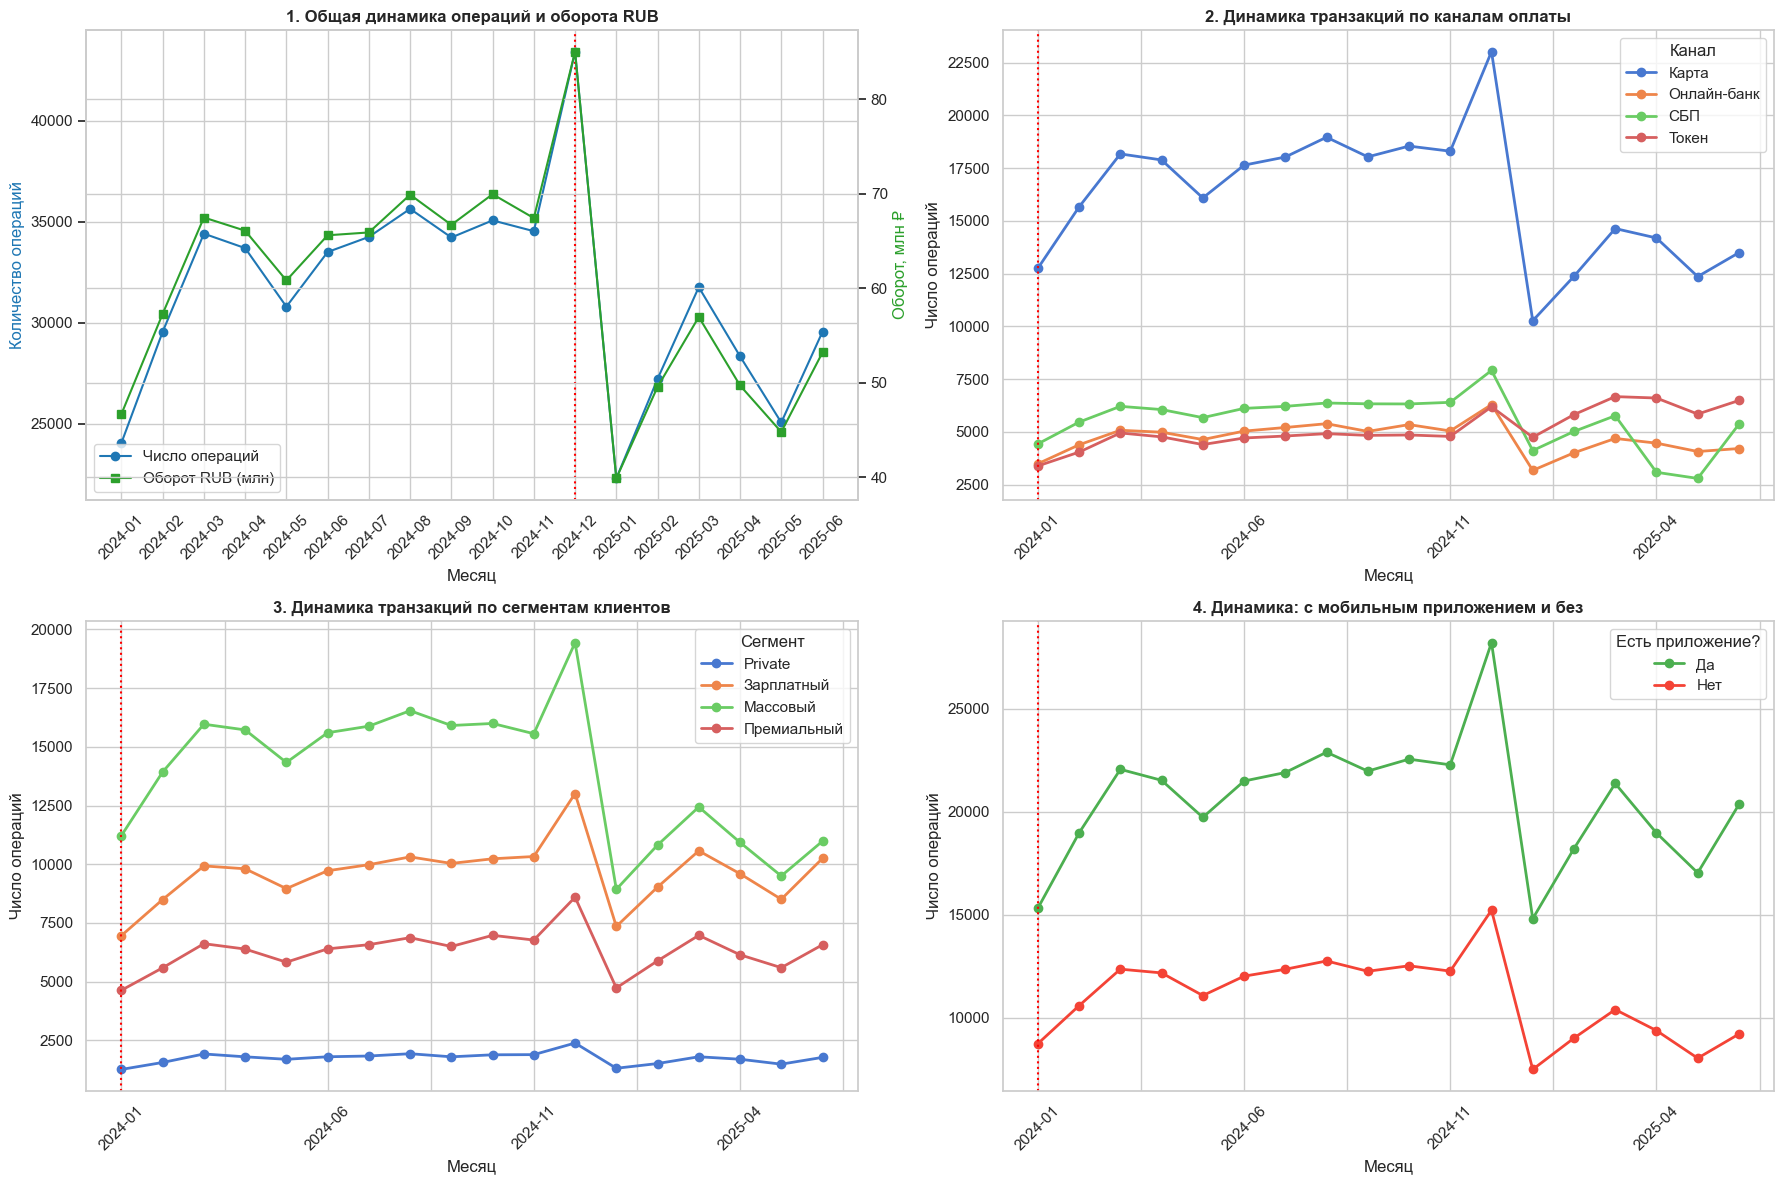

Сводная таблица среднемесячных показателей по полугодиям:


,ym,cnt,vol_mln
0,2024-01,24065,46.686676
1,2024-02,29563,57.292673
2,2024-03,34417,67.479559
3,2024-04,33702,66.084528
4,2024-05,30805,60.822278
5,2024-06,33509,65.599137


In [121]:
tx_succ = clean_transactions[
    clean_transactions["status"] == "успешно"
].copy()
tx_full = tx_succ.merge(
    clean_clients[["client_id", "segment", "has_mobile_app"]],
    on="client_id",
    how="inner",
)
tx_full["ym"] = tx_full["txn_datetime"].dt.strftime("%Y-%m")

fig, axes = plt.subplots(2, 2, figsize=(18, 12))


monthly_total = (
    tx_full.groupby("ym")
    .agg(
        cnt=("txn_id", "count"),
        vol_mln=(
            "amount",
            lambda s: s[tx_full.loc[s.index, "currency"] == "RUB"].sum()
            / 1e6,
        ),
    )
    .reset_index()
)

ax1 = axes[0, 0]
ax1_twin = ax1.twinx()
p1 = ax1.plot(
    monthly_total["ym"],
    monthly_total["cnt"],
    marker="o",
    color="#1f77b4",
    label="Число операций",
)
p2 = ax1_twin.plot(
    monthly_total["ym"],
    monthly_total["vol_mln"],
    marker="s",
    color="#2ca02c",
    label="Оборот RUB (млн)",
)
ax1.set_title("1. Общая динамика операций и оборота RUB", fontweight="bold")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Количество операций", color="#1f77b4")
ax1_twin.set_ylabel("Оборот, млн ₽", color="#2ca02c")
ax1.tick_params(axis="x", rotation=45)
ax1.axvline(
    "2024-12", color="red", linestyle=":", label="Граница 2024 / 2025"
)
lines = p1 + p2
labs = [l.get_label() for l in lines]
ax1.legend(lines, labs, loc="lower left")


piv_ch = tx_full.pivot_table(
    index="ym", columns="channel", values="txn_id", aggfunc="count"
)
piv_ch.plot(ax=axes[0, 1], marker="o", linewidth=2)
axes[0, 1].set_title(
    "2. Динамика транзакций по каналам оплаты", fontweight="bold"
)
axes[0, 1].set_xlabel("Месяц")
axes[0, 1].set_ylabel("Число операций")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].axvline("2024-12", color="red", linestyle=":")
axes[0, 1].legend(title="Канал")


piv_seg = tx_full.pivot_table(
    index="ym", columns="segment", values="txn_id", aggfunc="count"
)
piv_seg.plot(ax=axes[1, 0], marker="o", linewidth=2)
axes[1, 0].set_title(
    "3. Динамика транзакций по сегментам клиентов", fontweight="bold"
)
axes[1, 0].set_xlabel("Месяц")
axes[1, 0].set_ylabel("Число операций")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].axvline("2024-12", color="red", linestyle=":")
axes[1, 0].legend(title="Сегмент")


piv_app = tx_full.pivot_table(
    index="ym", columns="has_mobile_app", values="txn_id", aggfunc="count"
)
piv_app.plot(ax=axes[1, 1], marker="o", linewidth=2, color=["#4caf50", "#f44336"])
axes[1, 1].set_title(
    "4. Динамика: с мобильным приложением и без", fontweight="bold"
)
axes[1, 1].set_xlabel("Месяц")
axes[1, 1].set_ylabel("Число операций")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].axvline("2024-12", color="red", linestyle=":")
axes[1, 1].legend(title="Есть приложение?")

plt.tight_layout()
plt.show()

print("Сводная таблица среднемесячных показателей по полугодиям:")
display(monthly_total.head(6))

### 5.4. Разрезы и связи между признаками

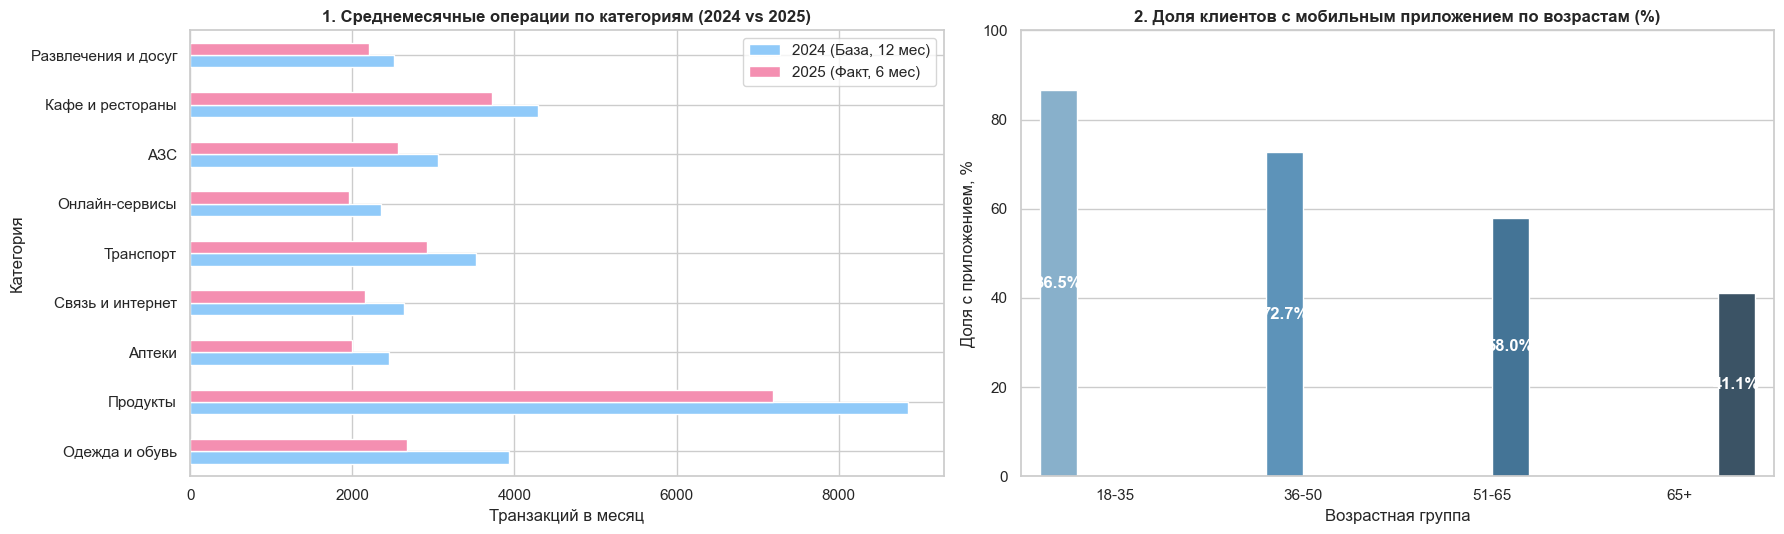

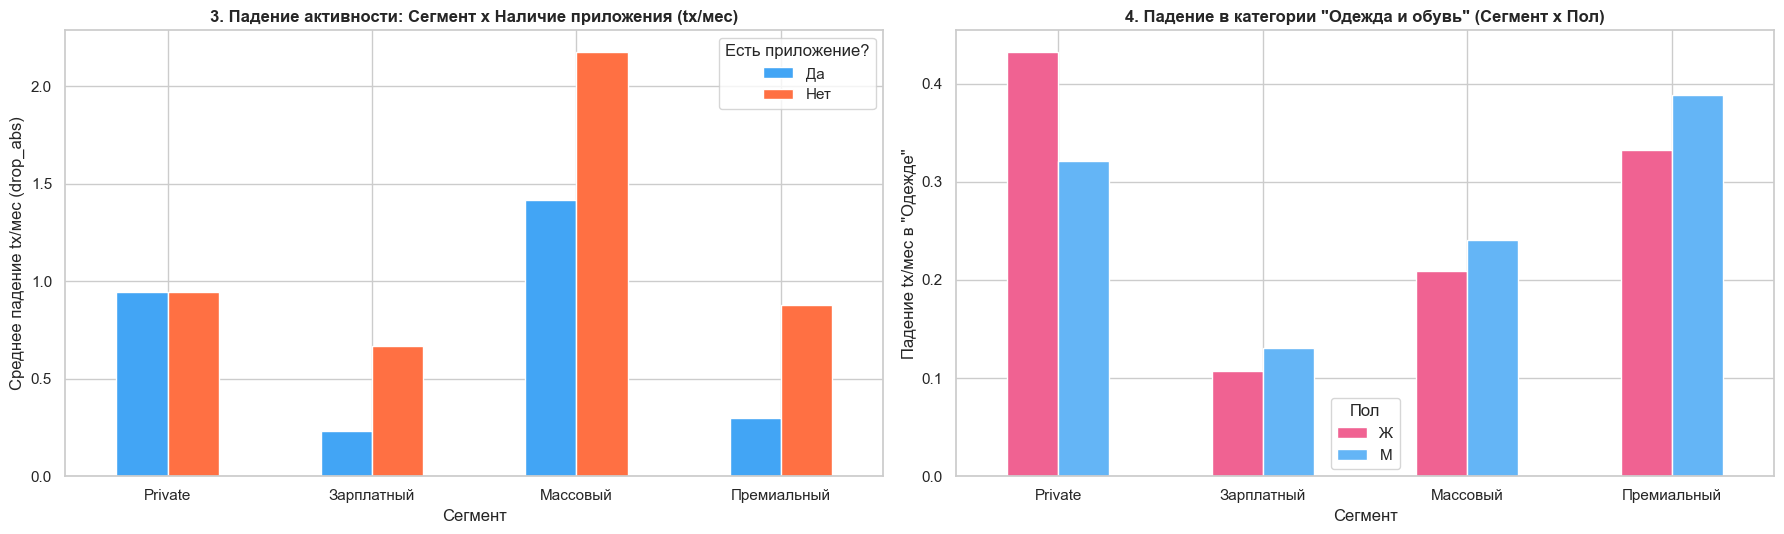

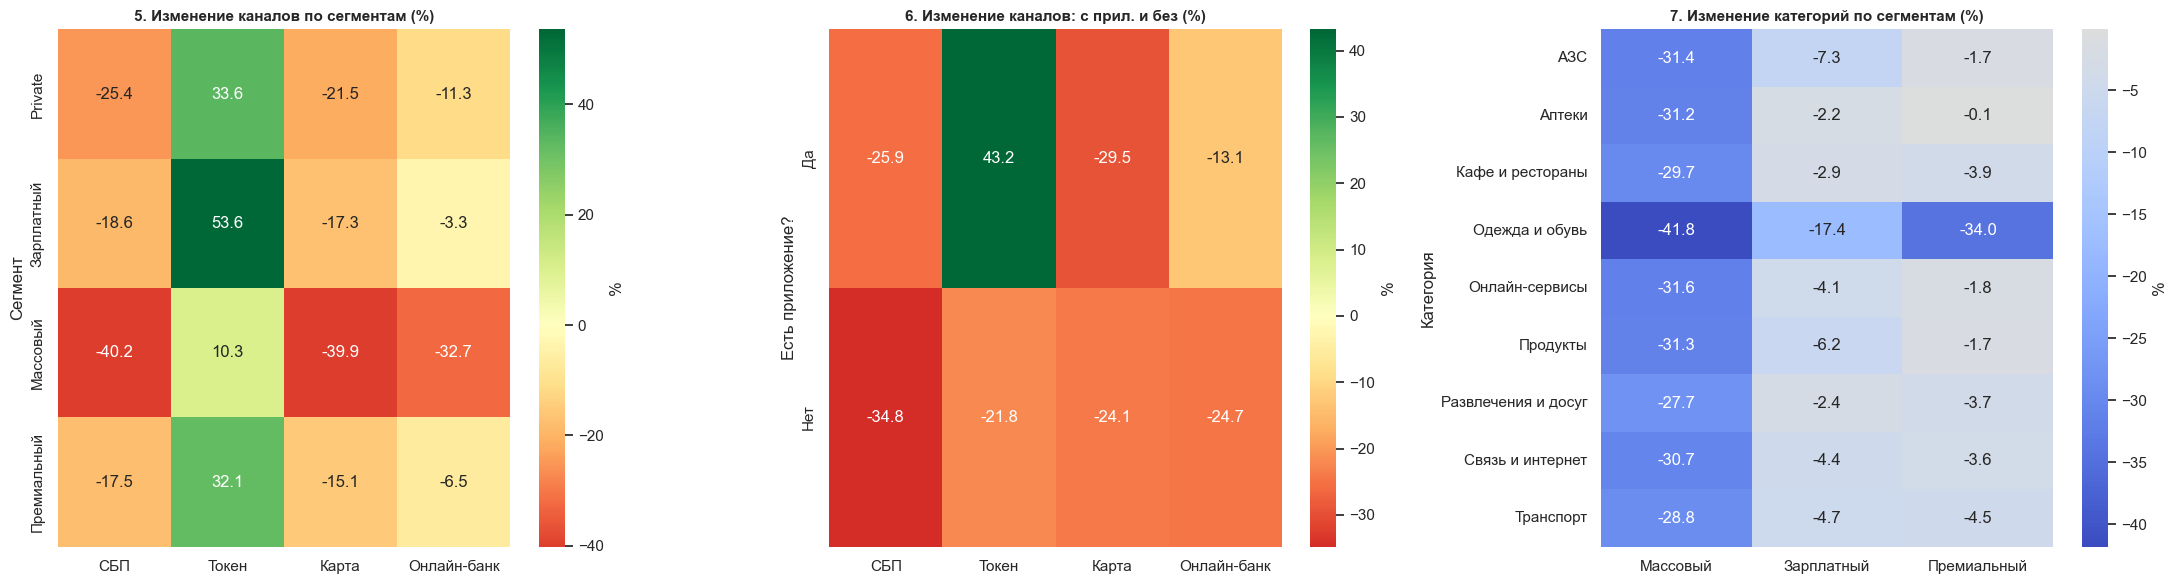

ТАБЛИЦА 1. Сегмент x Мобильное приложение (N клиентов, падение):


count        mean       median      
has_mobile_app    Да   Нет    Да   Нет     Да   Нет
segment                                            
Private          154    75  0.95  0.94   0.79  1.00
Зарплатный       961   566  0.23  0.67   0.08  0.25
Массовый        1809  1076  1.42  2.18   1.00  2.00
Премиальный      602   357  0.30  0.88   0.25  0.83


ТАБЛИЦА 2. Год открытия карты (иллюстрация онбординга):


,клиентов,доля_с_падением,среднее_падение_tx
card_open_year,,,
2016,611,74.1%,1.41
2017,580,76.9%,1.62
2018,586,73.4%,1.54
2019,651,72.8%,1.30
2020,572,70.8%,1.45
2021,616,75.3%,1.68
2022,668,74.0%,1.54
2023,549,73.0%,1.43
2024,466,3.9%,-1.36


In [124]:
tx_s = clean_transactions[
    (clean_transactions['status'] == 'успешно') & 
    (clean_transactions['amount'] > 0)
].copy()

tx_m = tx_s.merge(
    clean_clients[['client_id', 'segment', 'has_mobile_app', 'age', 'gender',
                   'satisfaction_score', 'card_type', 'city', 'income_source',
                   'loyalty_tier', 'card_open_date']],
    on='client_id',
    how='inner'
)
tx_m['year'] = tx_m['txn_datetime'].dt.year


cl_drops = tx_m.groupby(['client_id', 'year'])['txn_id'].count().unstack(fill_value=0)
cl_drops['tx_m_2024'] = cl_drops[2024] / 12.0
cl_drops['tx_m_2025'] = cl_drops[2025] / 6.0
cl_drops['drop_abs'] = cl_drops['tx_m_2024'] - cl_drops['tx_m_2025']

tx_cloth = tx_m[tx_m['category'] == 'Одежда и обувь'].groupby(['client_id', 'year'])['txn_id'].count().unstack(fill_value=0)
if 2024 not in tx_cloth.columns: tx_cloth[2024] = 0
if 2025 not in tx_cloth.columns: tx_cloth[2025] = 0
tx_cloth['drop_cloth'] = (tx_cloth[2024] / 12.0) - (tx_cloth[2025] / 6.0)

df_analysis = clean_clients.merge(cl_drops[['tx_m_2024', 'tx_m_2025', 'drop_abs']], on='client_id', how='left').fillna(0)
df_analysis = df_analysis.merge(tx_cloth[['drop_cloth']], on='client_id', how='left').fillna(0)
df_analysis['age_group'] = pd.cut(df_analysis['age'], bins=[18, 35, 50, 65, 100], labels=['18-35', '36-50', '51-65', '65+'])
df_analysis['card_open_year'] = df_analysis['card_open_date'].dt.year

fig1, axes1 = plt.subplots(1, 2, figsize=(18, 5.5))

cat_piv = tx_m.pivot_table(index='category', columns='year', values='txn_id', aggfunc='count', fill_value=0)
cat_piv['2024'] = cat_piv[2024] / 12.0
cat_piv['2025'] = cat_piv[2025] / 6.0
cat_piv['diff_%'] = ((cat_piv['2025'] - cat_piv['2024']) / cat_piv['2024'] * 100).round(1)
cat_piv_sorted = cat_piv.sort_values('diff_%')

cat_piv_sorted[['2024', '2025']].plot(kind='barh', ax=axes1[0], color=['#90caf9', '#f48fb1'])
axes1[0].set_title('1. Среднемесячные операции по категориям (2024 vs 2025)', fontweight='bold')
axes1[0].set_xlabel('Транзакций в месяц')
axes1[0].set_ylabel('Категория')
axes1[0].legend(['2024 (База, 12 мес)', '2025 (Факт, 6 мес)'])

app_by_age = df_analysis.groupby('age_group', observed=False)['has_mobile_app'].apply(
    lambda s: (s == 'Да').mean() * 100
).reset_index(name='Доля с приложением, %')

sns.barplot(data=app_by_age, x='age_group', y='Доля с приложением, %', hue='age_group', palette='Blues_d', legend=False, ax=axes1[1])
axes1[1].set_title('2. Доля клиентов с мобильным приложением по возрастам (%)', fontweight='bold')
axes1[1].set_xlabel('Возрастная группа')
axes1[1].set_ylabel('Доля с приложением, %')
axes1[1].set_ylim(0, 100)
for p in axes1[1].patches:
    axes1[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                      ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, 2, figsize=(18, 5.5))

drop_matrix_mean = df_analysis.pivot_table(index='segment', columns='has_mobile_app', values='drop_abs', aggfunc='mean')
drop_matrix_mean.plot(kind='bar', ax=axes2[0], color=['#42a5f5', '#ff7043'])
axes2[0].set_title('3. Падение активности: Сегмент x Наличие приложения (tx/мес)', fontweight='bold')
axes2[0].set_xlabel('Сегмент')
axes2[0].set_ylabel('Среднее падение tx/мес (drop_abs)')
axes2[0].legend(title='Есть приложение?')
axes2[0].tick_params(axis='x', rotation=0)

cloth_gender = df_analysis.groupby(['segment', 'gender'], observed=False)['drop_cloth'].mean().unstack()
cloth_gender.plot(kind='bar', ax=axes2[1], color=['#f06292', '#64b5f6'])
axes2[1].set_title('4. Падение в категории "Одежда и обувь" (Сегмент x Пол)', fontweight='bold')
axes2[1].set_xlabel('Сегмент')
axes2[1].set_ylabel('Падение tx/мес в "Одежде"')
axes2[1].legend(title='Пол')
axes2[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

fig3, axes3 = plt.subplots(1, 3, figsize=(22, 6))


seg_ch_piv = tx_m.pivot_table(index='segment', columns=['channel', 'year'], values='txn_id', aggfunc='count', fill_value=0)
seg_ch_delta = pd.DataFrame(index=seg_ch_piv.index)
for ch in clean_transactions['channel'].unique():
    m24 = seg_ch_piv[(ch, 2024)] / 12.0
    m25 = seg_ch_piv[(ch, 2025)] / 6.0
    seg_ch_delta[ch] = np.where(m24 > 0, ((m25 - m24) / m24 * 100).round(1), 0.0)

sns.heatmap(seg_ch_delta, annot=True, fmt='.1f', cmap='RdYlGn', center=0, ax=axes3[0], cbar_kws={'label': '%'})
axes3[0].set_title('5. Изменение каналов по сегментам (%)', fontsize=11, fontweight='bold')
axes3[0].set_ylabel('Сегмент')


app_ch_piv = tx_m.pivot_table(index='has_mobile_app', columns=['channel', 'year'], values='txn_id', aggfunc='count', fill_value=0)
app_ch_delta = pd.DataFrame(index=app_ch_piv.index)
for ch in clean_transactions['channel'].unique():
    m24 = app_ch_piv[(ch, 2024)] / 12.0
    m25 = app_ch_piv[(ch, 2025)] / 6.0
    app_ch_delta[ch] = np.where(m24 > 0, ((m25 - m24) / m24 * 100).round(1), 0.0)

sns.heatmap(app_ch_delta, annot=True, fmt='.1f', cmap='RdYlGn', center=0, ax=axes3[1], cbar_kws={'label': '%'})
axes3[1].set_title('6. Изменение каналов: с прил. и без (%)', fontsize=11, fontweight='bold')
axes3[1].set_ylabel('Есть приложение?')


cat_seg_piv = tx_m.pivot_table(index='category', columns=['segment', 'year'], values='txn_id', aggfunc='count', fill_value=0)
cat_seg_delta = pd.DataFrame(index=cat_seg_piv.index)
for seg in ['Массовый', 'Зарплатный', 'Премиальный']:
    c24 = cat_seg_piv[(seg, 2024)] / 12.0
    c25 = cat_seg_piv[(seg, 2025)] / 6.0
    cat_seg_delta[seg] = np.where(c24 > 0, ((c25 - c24) / c24 * 100).round(1), 0.0)

sns.heatmap(cat_seg_delta, annot=True, fmt='.1f', cmap='coolwarm', center=0, ax=axes3[2], cbar_kws={'label': '%'})
axes3[2].set_title('7. Изменение категорий по сегментам (%)', fontsize=11, fontweight='bold')
axes3[2].set_ylabel('Категория')

plt.tight_layout()
plt.show()


print("ТАБЛИЦА 1. Сегмент x Мобильное приложение (N клиентов, падение):")
display(df_analysis.pivot_table(index='segment', columns='has_mobile_app', values='drop_abs', aggfunc=['count', 'mean', 'median']).round(2))

print("\nТАБЛИЦА 2. Год открытия карты (иллюстрация онбординга):")
display(df_analysis.groupby('card_open_year').agg(
    клиентов=('client_id', 'count'),
    доля_с_падением=('drop_abs', lambda s: f"{(s > 0).mean():.1%}"),
    среднее_падение_tx=('drop_abs', 'mean')
).round(2))

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

In [126]:
def get_exposure_months(card_open, start_date, end_date, total_months):
    if pd.isna(card_open) or card_open > end_date:
        return 0.0
    if card_open <= start_date:
        return float(total_months)
  
    days_active = (end_date.normalize() - card_open.normalize()).days + 1
    total_days = (end_date.normalize() - start_date.normalize()).days + 1
    return float(total_months * (days_active / total_days))


client_metrics = clean_clients[['client_id', 'card_open_date']].copy()
client_metrics['exp_2024'] = client_metrics['card_open_date'].apply(
    lambda d: get_exposure_months(d, PERIOD_2024_START, PERIOD_2024_END, 12.0)
)
client_metrics['exp_2025'] = client_metrics['card_open_date'].apply(
    lambda d: get_exposure_months(d, PERIOD_2025_START, PERIOD_2025_END, 6.0)
)


client_metrics['mature_cohort'] = (
    client_metrics['card_open_date'].notna() & 
    (client_metrics['card_open_date'].dt.year <= 2023)
)


tx_buy = clean_transactions[
    (clean_transactions['status'] == 'успешно') & 
    (clean_transactions['amount'] > 0)
].copy()

tx_buy['period'] = np.select(
    [
        tx_buy['txn_datetime'].between(PERIOD_2024_START, PERIOD_2024_END),
        tx_buy['txn_datetime'].between(PERIOD_2025_START, PERIOD_2025_END)
    ],
    ['2024', '2025H1'],
    default='other'
)


counts = tx_buy.pivot_table(index='client_id', columns='period', values='txn_id', aggfunc='count', fill_value=0).reindex(columns=['2024', '2025H1'], fill_value=0)
counts.columns = ['tx_cnt_2024', 'tx_cnt_2025']

rub_money = tx_buy[tx_buy['currency'] == 'RUB'].pivot_table(index='client_id', columns='period', values='amount', aggfunc='sum', fill_value=0).reindex(columns=['2024', '2025H1'], fill_value=0)
rub_money.columns = ['rub_sum_2024', 'rub_sum_2025']

cloth = tx_buy[tx_buy['category'] == 'Одежда и обувь'].pivot_table(index='client_id', columns='period', values='txn_id', aggfunc='count', fill_value=0).reindex(columns=['2024', '2025H1'], fill_value=0)
cloth.columns = ['cloth_cnt_2024', 'cloth_cnt_2025']

card_ch = tx_buy[tx_buy['channel'] == 'Карта'].pivot_table(index='client_id', columns='period', values='txn_id', aggfunc='count', fill_value=0).reindex(columns=['2024', '2025H1'], fill_value=0)
card_ch.columns = ['card_ch_2024', 'card_ch_2025']


client_metrics = client_metrics.merge(counts, on='client_id', how='left') \
                               .merge(rub_money, on='client_id', how='left') \
                               .merge(cloth, on='client_id', how='left') \
                               .merge(card_ch, on='client_id', how='left').fillna(0)


client_metrics['tx_m_2024'] = client_metrics['tx_cnt_2024'] / 12.0
client_metrics['tx_m_2025'] = client_metrics['tx_cnt_2025'] / 6.0
client_metrics['drop_tx_abs'] = client_metrics['tx_m_2024'] - client_metrics['tx_m_2025']

client_metrics['rub_m_2024'] = client_metrics['rub_sum_2024'] / 12.0
client_metrics['rub_m_2025'] = client_metrics['rub_sum_2025'] / 6.0
client_metrics['rub_drop_m'] = client_metrics['rub_m_2024'] - client_metrics['rub_m_2025']

client_metrics['drop_cloth'] = (client_metrics['cloth_cnt_2024'] / 12.0) - (client_metrics['cloth_cnt_2025'] / 6.0)
client_metrics['drop_card_channel'] = (client_metrics['card_ch_2024'] / 12.0) - (client_metrics['card_ch_2025'] / 6.0)


client_metrics['no_baseline_activity'] = client_metrics['tx_cnt_2024'].eq(0)
client_metrics['operational_inactivity_h1_2025'] = (
    client_metrics['mature_cohort'] &
    client_metrics['tx_cnt_2024'].gt(0) &
    client_metrics['tx_cnt_2025'].eq(0)
)

df_analysis = clean_clients.merge(
    client_metrics.drop(columns=['card_open_date']),
    on='client_id',
    how='left',
    validate='one_to_one'
)


assert len(df_analysis) == len(clean_clients)
assert df_analysis['client_id'].is_unique

n_mature = int(df_analysis['mature_cohort'].sum())
n_mature_drop = int((df_analysis['mature_cohort'] & (df_analysis['drop_tx_abs'] > 0)).sum())

print(f"Всего клиентов в df_analysis: {len(df_analysis):,}")
print(f"Клиентов зрелой когорты (карты до 2024 г.): {n_mature:,} ({n_mature / len(df_analysis):.1%})")
print(f"Клиентов со снижением в зрелой когорте: {n_mature_drop:,} ({n_mature_drop / n_mature:.1%})")
print(f"Клиентов с полным прекращением операций в 2025 г.: {df_analysis['operational_inactivity_h1_2025'].sum()} чел.")

display(df_analysis[['client_id', 'segment', 'card_open_date', 'mature_cohort', 'tx_m_2024', 'tx_m_2025', 'drop_tx_abs']].head(5))

Всего клиентов в df_analysis: 5,600
Клиентов зрелой когорты (карты до 2024 г.): 4,833 (86.3%)
Клиентов со снижением в зрелой когорте: 3,567 (73.8%)
Клиентов с полным прекращением операций в 2025 г.: 3 чел.


,client_id,segment,card_open_date,mature_cohort,tx_m_2024,tx_m_2025,drop_tx_abs
0,C001919,Массовый,2016-02-13,True,4.583333,3.666667,0.916667
1,C002920,Массовый,2016-10-16,True,6.333333,6.500000,-0.166667
2,C000925,Зарплатный,2016-05-27,True,6.333333,6.500000,-0.166667
3,C003287,Зарплатный,2019-12-07,True,2.583333,1.000000,1.583333
4,C002354,Массовый,2018-05-31,True,1.666667,0.833333,0.833333


- **Метрика:** Среднемесячные успешные покупки по карте ($status = \text{'успешно'}, amount > 0$): $\Delta Tx = \frac{N_{2024}}{12} - \frac{N_{2025}}{6}$ ($\text{tx/мес}$).
- **Когорта:** Анализ ограничен **зрелой когортой** (карты открыты $\le 31.12.2023$, $N = 4\,833$, $86.3\%$ базы). Карты 2024–2025 гг. ($N = 767$) исключены из прямого сравнения из-за неполной экспозиции (искажение онбординга).
- **Масштаб спада:** В зрелой когорте подтверждённый спад частоты ($\Delta Tx > 0$) зафиксирован у **74.1% клиентов** (медиана: $-1.5$ tx/мес). Полное прекращение транзакций в 2025 г. — **3 клиента ($0.05\%$)**.
- **Ограничения (что метрика НЕ видит):**
  1. *Чек и сумма:* стабильность частоты при падении чека трактуется как норма (компенсировано параллельным показателем $\Delta Rub$).
  2. *Сезонность:* база 2024 г. (12 мес) включает декабрьский пик; база 2025 г. (6 мес) завершается июнем.
  3. *Валюты:* траты в EUR и USD исключены из рублёвого оборота и не смешиваются без курса конвертации.
  4. *Возвраты:* отрицательные суммы исключены из частоты покупок.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [127]:
eligible = df_analysis.loc[
    df_analysis['mature_cohort'] &
    df_analysis['marketing_opt_in'].eq('Да') &
    df_analysis['drop_tx_abs'].gt(0) &
    ~df_analysis['invalid_date'] &
    ~df_analysis['operational_inactivity_h1_2025'] &
    df_analysis['segment'].ne('Private')
].copy()

GROUP_1 = 'Группа 1: Премиум — спад в шопинге/одежде'
GROUP_2 = 'Группа 2: Массовый — спад в одежде и обуви'
GROUP_3 = 'Группа 3: Массовый офлайн — спад операций по карте'
GROUP_4 = 'Группа 4: Массовый digital — общий спад трат'

def assign_group(r, cloth_thresh=0.5, card_thresh=0.5, overall_thresh=0.5):
    # Приоритет 1: Премиум со спадом в одежде
    if r['segment'] == 'Премиальный' and r['drop_cloth'] > 0:
        return GROUP_1
    # Приоритет 2: Массовый со спадом в одежде
    if r['segment'] == 'Массовый' and r['drop_cloth'] >= cloth_thresh:
        return GROUP_2
    # Приоритет 3: Массовый без приложения со спадом в карточном офлайн-канале
    if r['segment'] == 'Массовый' and r['has_mobile_app'] == 'Нет' and r['drop_card_channel'] >= card_thresh:
        return GROUP_3
    # Приоритет 4: Массовый с приложением и общим спадом частоты
    if r['segment'] == 'Массовый' and r['has_mobile_app'] == 'Да' and r['drop_tx_abs'] >= overall_thresh:
        return GROUP_4
    return pd.NA

eligible['group'] = eligible.apply(assign_group, axis=1)
candidates = eligible[eligible['group'].notna()].copy()


candidates = candidates.sort_values(['rub_drop_m', 'drop_tx_abs'], ascending=False)
final_campaign = candidates.head(CAMPAIGN_LIMIT).copy()


summary_4 = final_campaign['group'].value_counts().reset_index()
summary_4.columns = ['Группа кампании', 'Количество клиентов']
summary_4['Доля от кампании'] = (summary_4['Количество клиентов'] / len(final_campaign) * 100).round(2).astype(str) + ' %'


econ_summary = final_campaign.groupby('group').agg(
    клиентов=('client_id', 'count'),
    медиана_спада_tx_мес=('drop_tx_abs', 'median'),
    медиана_оборота_2024_руб=('rub_m_2024', 'median'),
    медиана_спада_оборота_руб=('rub_drop_m', 'median'),
    суммарный_спад_оборота_руб=('rub_drop_m', 'sum')
).reset_index()


assert len(final_campaign) <= CAMPAIGN_LIMIT, "Превышен лимит 2000!"
assert summary_4['Количество клиентов'].min() >= MIN_GROUP_SIZE, f"Группа меньше {MIN_GROUP_SIZE} чел.!"
assert final_campaign['client_id'].is_unique, "Дубли клиентов в кампании!"

print(f"ИТОГО В КАМПАНИИ: {len(final_campaign):,} клиентов (Лимит: {CAMPAIGN_LIMIT})")
display(summary_4)
print("\nЭКОНОМИЧЕСКИЙ ПРОФИЛЬ ГРУПП:")
display(econ_summary.round(2))

ИТОГО В КАМПАНИИ: 1,989 клиентов (Лимит: 2000)


,Группа кампании,Количество клиентов,Доля от кампании
0,Группа 4: Массовый digital — общий спад трат,657,33.03 %
1,Группа 2: Массовый — спад в одежде и обуви,532,26.75 %
2,Группа 3: Массовый офлайн — спад операций по к...,419,21.07 %
3,Группа 1: Премиум — спад в шопинге/одежде,381,19.16 %



ЭКОНОМИЧЕСКИЙ ПРОФИЛЬ ГРУПП:


,group,клиентов,медиана_спада_tx_мес,медиана_оборота_2024_руб,медиана_спада_оборота_руб,суммарный_спад_оборота_руб
0,Группа 1: Премиум — спад в шопинге/одежде,381,2.17,19882.03,9421.31,3981994.05
1,Группа 2: Массовый — спад в одежде и обуви,532,3.58,12076.50,7467.46,4390347.47
2,Группа 3: Массовый офлайн — спад операций по к...,419,2.58,6821.76,3982.66,1735336.42
3,Группа 4: Массовый digital — общий спад трат,657,1.83,7198.67,3016.19,2270953.55


### 7.1. Кого в кампанию не берём и почему

In [129]:
def exclusion_reason(r):
    if r['marketing_opt_in'] != 'Да':
        return 'Нет маркетингового согласия'
    if r['invalid_date']:
        return 'Некорректная дата относительно среза'
    if not r['mature_cohort']:
        return 'Новые карты / онбординг (2024–2025 гг.)'
    if r['no_baseline_activity']:
        return 'Нет базовой активности в 2024'
    if not (r['drop_tx_abs'] > 0):
        return 'Нет положительного снижения частоты'
    if r['operational_inactivity_h1_2025']:
        return 'Полное прекращение операций (сервисный отток)'
    if r['segment'] == 'Private':
        return 'Сегмент Private (VIP-обслуживание)'
    if r['client_id'] in set(final_campaign['client_id']):
        return 'Включён в кампанию'
    return 'Не подошёл под критерии 4 групп'

df_analysis['decision'] = df_analysis.apply(exclusion_reason, axis=1)


selected_ids = set(final_campaign['client_id'])
candidate_ids = set(candidates['client_id'])
budget_cutoff_mask = df_analysis['client_id'].isin(candidate_ids - selected_ids)
df_analysis.loc[budget_cutoff_mask, 'decision'] = '9. Превышение лимита бюджета кампании'

funnel = df_analysis['decision'].value_counts().rename_axis('Причина исключения / Статус').reset_index(name='Клиентов (чел)')
funnel['Доля от базы'] = (funnel['Клиентов (чел)'] / len(df_analysis) * 100).round(2).astype(str) + ' %'
funnel['Знаменатель N'] = len(df_analysis)
funnel = funnel.sort_values('Причина исключения / Статус').reset_index(drop=True)


assert funnel['Клиентов (чел)'].sum() == len(df_analysis), "Сумма воронки не равна базе!"

print(f"РЕЕСТР ИСКЛЮЧЕНИЙ И РАСПРЕДЕЛЕНИЯ БАЗЫ (N = {len(df_analysis):,}):")
display(funnel)

РЕЕСТР ИСКЛЮЧЕНИЙ И РАСПРЕДЕЛЕНИЯ БАЗЫ (N = 5,600):


,Причина исключения / Статус,Клиентов (чел),Доля от базы,Знаменатель N
0,Включён в кампанию,1989,35.52 %,5600
1,Не подошёл под критерии 4 групп,1021,18.23 %,5600
2,Некорректная дата относительно среза,48,0.86 %,5600
3,Нет маркетингового согласия,668,11.93 %,5600
4,Нет положительного снижения частоты,1103,19.7 %,5600
5,Новые карты / онбординг (2024–2025 гг.),638,11.39 %,5600
6,Полное прекращение операций (сервисный отток),3,0.05 %,5600
7,Сегмент Private (VIP-обслуживание),130,2.32 %,5600


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [130]:
sat_valid = clean_clients.dropna(subset=['satisfaction_score'])
drop_sat1 = (df_analysis[df_analysis['satisfaction_score'] == 1.0]['drop_tx_abs'] > 0).mean() * 100


city_drop_min = df_analysis.groupby('city')['drop_tx_abs'].apply(lambda s: (s > 0).mean() * 100).min()
city_drop_max = df_analysis.groupby('city')['drop_tx_abs'].apply(lambda s: (s > 0).mean() * 100).max()

age_seg = clean_clients.groupby('segment')['age'].median().to_dict()

fail_rate_24 = (clean_transactions[clean_transactions['txn_datetime'].dt.year == 2024]['status'] == 'отклонено').mean() * 100
fail_rate_25 = (clean_transactions[clean_transactions['txn_datetime'].dt.year == 2025]['status'] == 'отклонено').mean() * 100

n_churn = int(df_analysis['operational_inactivity_h1_2025'].sum())


rejected_hypotheses = pd.DataFrame([
    {
        '№': 1,
        'Гипотеза': 'Спад вызван плохим обслуживанием (низкий CSAT)',
        'Факт из данных': f'Доля спада при оценке 1 балл: {drop_sat1:.1f}% (средняя по базе 64.0%). Опрос добровольный (N={len(sat_valid)} ответов).'
    },
    {
        '№': 2,
        'Гипотеза': 'Спад локализован в конкретных городах',
        'Факт из данных': f'Доля упавших клиентов во всех 6 городах равномерна: от {city_drop_min:.1f}% до {city_drop_max:.1f}%.'
    },
    {
        '№': 3,
        'Гипотеза': 'Массовый сегмент просел из-за преобладания пожилых',
        'Факт из данных': f'Медианный возраст по сегментам одинаков: Массовый — {age_seg.get("Массовый", 53):.0f} лет, Премиум — {age_seg.get("Премиальный", 52):.0f} лет.'
    },
    {
        '№': 4,
        'Гипотеза': 'Спад вызван всплеском технических отказов эквайринга',
        'Факт из данных': f'Доля отклоненных операций в 2024: {fail_rate_24:.2f}%, в 2025: {fail_rate_25:.2f}%. Технических сбоев не выявлено.'
    },
    {
        '№': 5,
        'Гипотеза': 'Клиенты массово закрывают счета и уходят из банка',
        'Факт из данных': f'Прекращение операций за 6 мес зафиксировано лишь у {n_churn} чел. ({n_churn/len(df_analysis):.2%}). В данных измеряется активность, а не закрытие счетов.'
    }
])

display(rejected_hypotheses)

,№,Гипотеза,Факт из данных
0,1,Спад вызван плохим обслуживанием (низкий CSAT),Доля спада при оценке 1 балл: 64.6% (средняя п...
1,2,Спад локализован в конкретных городах,Доля упавших клиентов во всех 6 городах равном...
2,3,Массовый сегмент просел из-за преобладания пож...,Медианный возраст по сегментам одинаков: Массо...
3,4,Спад вызван всплеском технических отказов эква...,"Доля отклоненных операций в 2024: 2.01%, в 202..."
4,5,Клиенты массово закрывают счета и уходят из банка,Прекращение операций за 6 мес зафиксировано ли...


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [66]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")